In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
np.set_printoptions(suppress=True)

In [ ]:
trans_df = pd.read_csv('/content/drive/MyDrive/Machine Learning/Projects/Fraud Detection Capstone Project/Datasets/Cleaned Dataset/cleaned_transaction_data.csv')
trans_df.head()

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.00,5499,NaN
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.00,5311,NaN
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.00,4829,NaN
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.00,4829,NaN
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.00,5813,NaN


In [ ]:
user_df = pd.read_csv('/content/drive/MyDrive/Machine Learning/Projects/Fraud Detection Capstone Project/Datasets/Cleaned Dataset/cleaned_user_data.csv')
user_df.head()

,id,current_age,retirement_age,birth_year,birth_month,gender,address,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
0,825,53,66,1966,11,Female,462 Rose Lane,34.15,-117.76,29278.00,59696.00,127613.00,787,5
1,1746,53,68,1966,12,Female,3606 Federal Boulevard,40.76,-73.74,37891.00,77254.00,191349.00,701,5
2,1718,81,67,1938,11,Female,766 Third Drive,34.02,-117.89,22681.00,33483.00,196.00,698,5
3,708,63,63,1957,1,Female,3 Madison Street,40.71,-73.99,163145.00,249925.00,202328.00,722,4
4,1164,43,70,1976,9,Male,9620 Valley Stream Drive,37.76,-122.44,53797.00,109687.00,183855.00,675,1


In [ ]:
card_df = pd.read_csv('/content/drive/MyDrive/Machine Learning/Projects/Fraud Detection Capstone Project/Datasets/Cleaned Dataset/cleaned_card_data.csv')
card_df.head()

,id,client_id,card_brand,card_type,card_number,expires,cvv,has_chip,num_cards_issued,credit_limit,acct_open_date,year_pin_last_changed
0,4524,825,Visa,Debit,4344676511950444,2022-12,623,True,2,24295.00,2002-09,2008
1,2731,825,Visa,Debit,4956965974959986,2020-12,393,True,2,21968.00,2014-04,2014
2,3701,825,Visa,Debit,4582313478255491,2024-02,719,True,2,46414.00,2003-07,2004
3,42,825,Visa,Credit,4879494103069057,2024-08,693,False,1,12400.00,2003-01,2012
4,4659,825,Mastercard,Debit (Prepaid),5722874738736011,2009-03,75,True,1,28.00,2008-09,2009


In [ ]:
fraud_df = pd.read_json('/content/drive/MyDrive/Machine Learning/Projects/Fraud Detection Capstone Project/Datasets/Transaction Fraud Detection/train_fraud_labels.json')
fraud_df.head()

,target
10649266,No
23410063,No
9316588,No
12478022,No
9558530,No


In [ ]:
fraud_df = fraud_df.reset_index().rename({'index':'id'}, axis=1)

# Individual EDA

In [ ]:
trans_df.head()

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.00,5499,NaN
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.00,5311,NaN
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.00,4829,NaN
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.00,4829,NaN
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.00,5813,NaN


In [ ]:
trans_df.shape

(13305915, 13)

### amount

In [ ]:
print(trans_df['amount'].skew())

5.221120380310039


<Axes: xlabel='amount', ylabel='Count'>

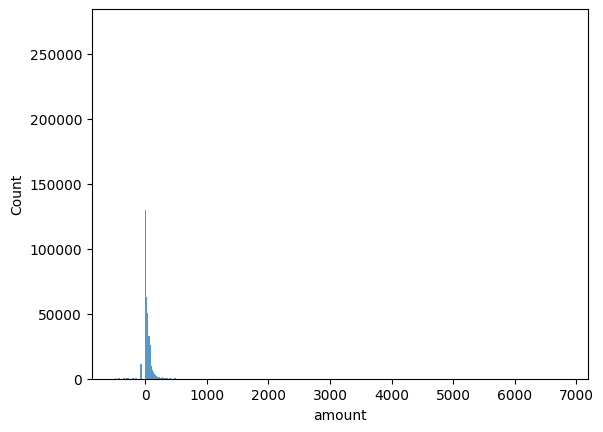

In [ ]:
sns.histplot(trans_df['amount'])

In [ ]:
trans_df['amount'].describe()

,amount
count,13305915.00
mean,42.98
std,81.66
min,-500.00
25%,8.93
50%,28.99
75%,63.71
max,6820.20


In [ ]:
(trans_df['amount'] < 0).sum()

np.int64(660049)

In [ ]:
df_pos = trans_df[trans_df['amount'] >= 0]

df_pos['log_amount'] = np.log1p(df_pos['amount'])

/tmp/ipykernel_30066/405210433.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_pos['log_amount'] = np.log1p(df_pos['amount'])


In [ ]:
df_pos.head()

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,log_amount
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.00,5311,NaN,2.75
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.00,4829,NaN,4.39
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.00,4829,NaN,5.30
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.00,5813,NaN,3.86
5,7475333,2010-01-01,00:07:00,1807,165,4.81,Swipe Transaction,20519,Bronx,NY,10464.00,5942,NaN,1.76


In [ ]:
df_pos['log_amount'].skew()

np.float64(-0.38137405426299414)

<Axes: xlabel='log_amount', ylabel='Count'>

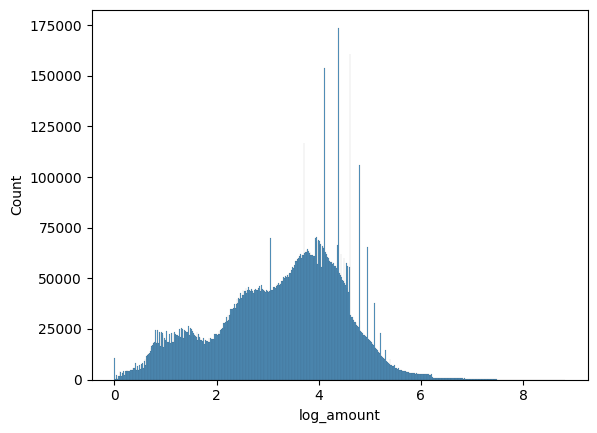

In [ ]:
sns.histplot(df_pos['log_amount'])

In [ ]:
trans_df[trans_df['amount'] < 0]

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.00,5499,NaN
19,7475347,2010-01-01,00:36:00,114,3398,-64.00,Swipe Transaction,61195,North Hollywood,CA,91606.00,5541,NaN
50,7475382,2010-01-01,01:25:00,1703,2969,-78.00,Swipe Transaction,43293,Grand Junction,CO,81506.00,5499,NaN
81,7475422,2010-01-01,02:13:00,1453,1117,-460.00,Swipe Transaction,5009,Middletown,NY,10940.00,7011,NaN
114,7475460,2010-01-01,03:08:00,957,4532,-147.00,Swipe Transaction,44795,Marysville,OH,43040.00,3780,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13305780,23761706,2019-10-31,22:13:00,1360,143,-91.00,Chip Transaction,59935,Crestview,FL,32536.00,5499,NaN
13305811,23761745,2019-10-31,22:28:00,194,5587,-71.00,Swipe Transaction,59935,Hartford City,IN,47348.00,5499,NaN
13305813,23761747,2019-10-31,22:29:00,133,4683,-52.00,Chip Transaction,61195,Marietta,GA,30067.00,5541,NaN
13305820,23761757,2019-10-31,22:35:00,260,323,-77.00,Chip Transaction,22204,Mission,TX,78572.00,5541,NaN


In [ ]:
trans_df['is_refund'] = (trans_df['amount'] < 0).astype(int)

In [ ]:
trans_df['abs_amount'] = abs(trans_df['amount'])

In [ ]:
trans_df.head()

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,is_refund,abs_amount
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.00,5499,NaN,1,77.00
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.00,5311,NaN,0,14.57
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.00,4829,NaN,0,80.00
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.00,4829,NaN,0,200.00
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.00,5813,NaN,0,46.41


In [ ]:
master_df = pd.merge(trans_df, fraud_df, on='id', how='left')

display(master_df.head())

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,is_refund,abs_amount,target
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.00,5499,NaN,1,77.00,No
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.00,5311,NaN,0,14.57,No
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.00,4829,NaN,0,80.00,No
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.00,4829,NaN,0,200.00,NaN
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.00,5813,NaN,0,46.41,No


In [ ]:
def downcast_dtypes(df, money_cols=None, skip_cols=None):
    money_cols = money_cols or []
    skip_cols = skip_cols or []

    for col in df.columns:
        if col in skip_cols or df[col].dtype.name in ('category',) or pd.api.types.is_datetime64_any_dtype(df[col]):
            continue
        if col in money_cols:
            df[col] = df[col].astype('float32')
        elif pd.api.types.is_integer_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast='integer')
        elif pd.api.types.is_float_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast='float')
    return df

master_df = downcast_dtypes(master_df, money_cols=['amount', 'abs_amount'])

In [ ]:
master_df['target'].value_counts()

,count
target,
No,8901631
Yes,13332


In [ ]:
fraud_df.shape

(8914963, 2)

In [ ]:
trans_df.shape

(13305915, 15)

In [ ]:
common_ids = set(trans_df['id']) & set(fraud_df['id'])

len(common_ids)

8914963

In [ ]:
master_df['target'].isna().mean() * 100

np.float64(33.00000037577273)

In [ ]:
master_df.head()

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,is_refund,abs_amount,target
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.00,5499,NaN,1,77.00,No
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.00,5311,NaN,0,14.57,No
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.00,4829,NaN,0,80.00,No
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.00,4829,NaN,0,200.00,NaN
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.00,5813,NaN,0,46.41,No


### use_chip

In [ ]:
master_df['use_chip'].value_counts(normalize=True)

,proportion
use_chip,
Swipe Transaction,0.52
Chip Transaction,0.36
Online Transaction,0.12


<Axes: xlabel='count', ylabel='use_chip'>

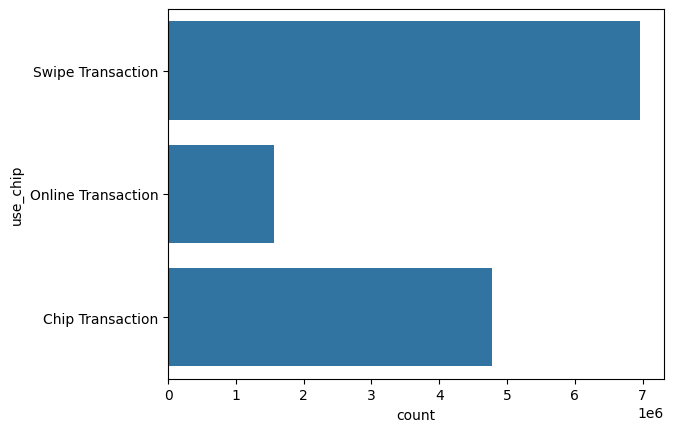

In [ ]:
sns.countplot(master_df['use_chip'])

- Swipe Transaction is done more

### merchant city

In [ ]:
master_df['merchant_city'].nunique()

12492

In [ ]:
top_10_city = master_df['merchant_city'].value_counts().head(11)[1:]

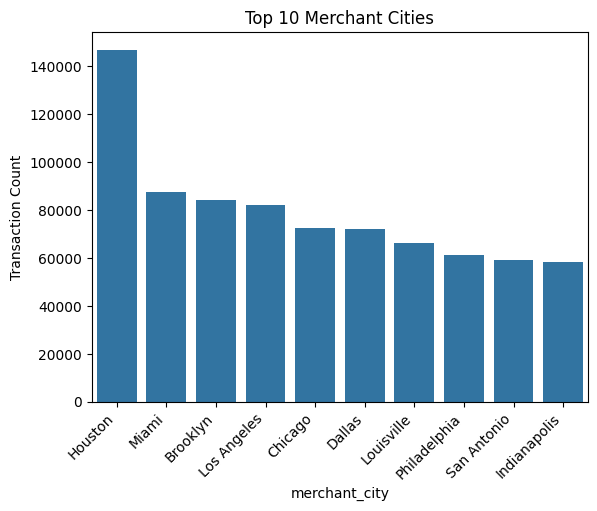

In [ ]:
sns.barplot(x=top_10_city.index, y=top_10_city.values)
plt.title('Top 10 Merchant Cities')
plt.xticks(rotation=45, ha="right")
plt.ylabel('Transaction Count')
plt.show()

- People do Online transactions more. Other than that, these are the top 10 cities where transactions are done more

In [ ]:
# Freeing up Ram

import gc
vars_to_del = ['trans_df', 'df_pos']

for var in vars_to_del:
    if var in globals():
        del globals()[var]

# Force garbage collection
gc.collect()

print("RAM cleared.")

RAM cleared.


In [ ]:
master_df['merchant_state'].nunique()

199

In [ ]:
top_10_states = master_df['merchant_state'].value_counts().head(10)

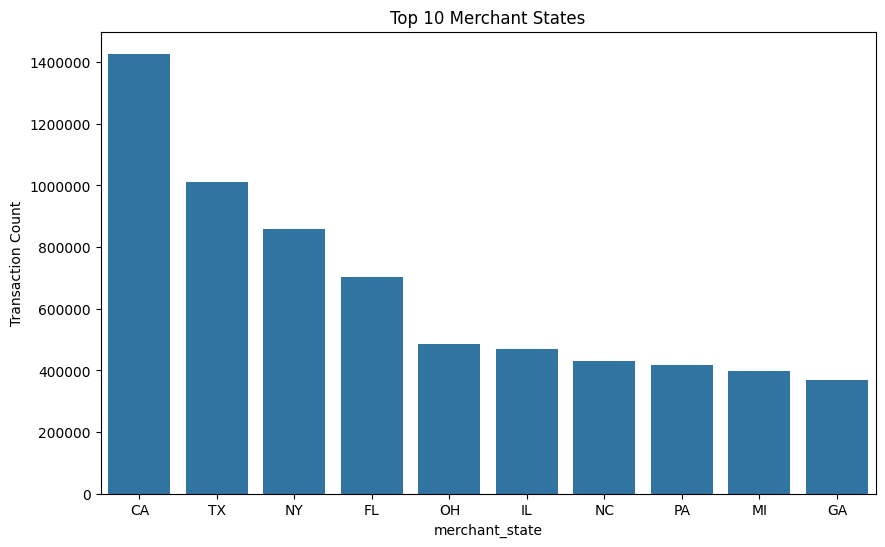

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_10_states.index, y=top_10_states.values)
plt.ticklabel_format(style='plain', axis='y')
plt.title('Top 10 Merchant States')
plt.ylabel('Transaction Count')
plt.show()

In [ ]:
master_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13305915 entries, 0 to 13305914
Data columns (total 16 columns):
 #   Column          Dtype  
---  ------          -----  
 0   id              int32  
 1   date            object 
 2   time            object 
 3   client_id       int16  
 4   card_id         int16  
 5   amount          float32
 6   use_chip        object 
 7   merchant_id     int32  
 8   merchant_city   object 
 9   merchant_state  object 
 10  zip             float32
 11  mcc             int16  
 12  errors          object 
 13  is_refund       int8   
 14  abs_amount      float32
 15  target          object 
dtypes: float32(3), int16(3), int32(2), int8(1), object(7)
memory usage: 1.0+ GB


- California (CA) and Texas (TX) have the highest transaction volumes.

In [ ]:
import gc
vars_to_del = ['fraud_df']

for var in vars_to_del:
    if var in globals():
        del globals()[var]

# Force garbage collection
gc.collect()

print("RAM cleared.")

RAM cleared.


In [ ]:
master_df['is_refund'].value_counts()

,count
is_refund,
0,12645866
1,660049


## Bivariate Analysis

In [ ]:
master_df.head()

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,is_refund,abs_amount,target
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.00,5499,NaN,1,77.00,No
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.00,5311,NaN,0,14.57,No
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.00,4829,NaN,0,80.00,No
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.00,4829,NaN,0,200.00,NaN
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.00,5813,NaN,0,46.41,No


### date vs fraud

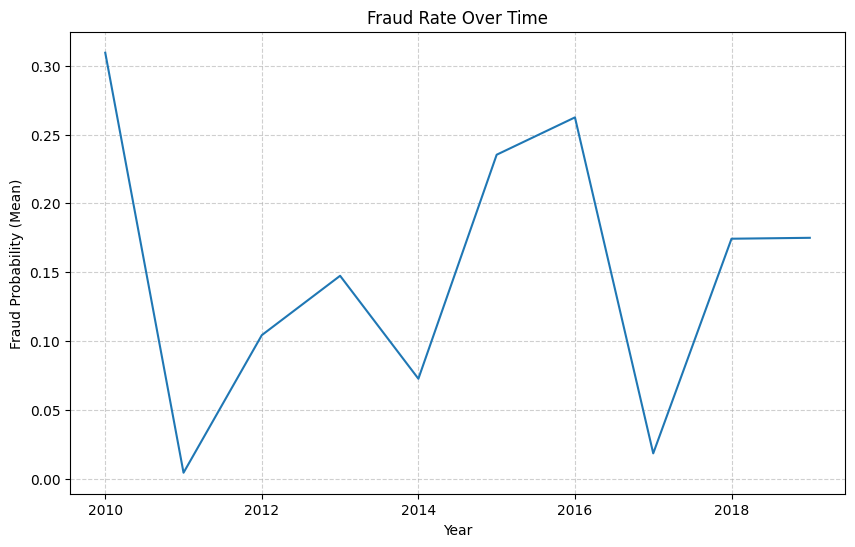

In [ ]:
master_df['date'] = pd.to_datetime(master_df['date'])

master_df['target_numeric'] = master_df['target'].map({'No': 0, 'Yes': 1})

fraud_yearly = (
    master_df
    .groupby(master_df['date'].dt.year)['target_numeric']
    .mean()
    * 100
)
plt.figure(figsize=(10, 6))
sns.lineplot(x = fraud_yearly.index, y=fraud_yearly.values, errorbar=None)
plt.title('Fraud Rate Over Time')
plt.ylabel('Fraud Probability (Mean)')
plt.xlabel('Year')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


* Fraud rates peaked in 2010 (0.31%) and 2016 (0.26%).
* Sharp drops occurred in 2011 and 2017.

### date vs use_chip

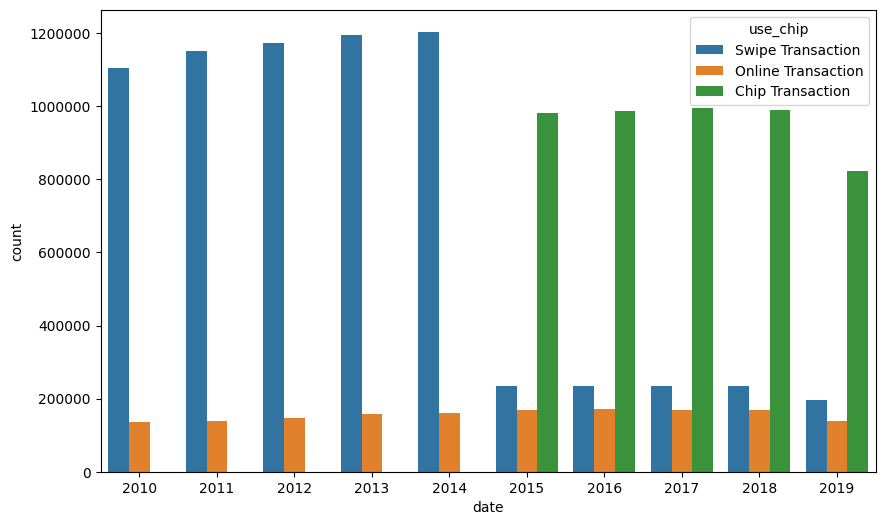

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(x = master_df['date'].dt.year, hue = master_df['use_chip'])
plt.ticklabel_format(style='plain', axis='y')
plt.show()

* **EMV Adoption:** A dramatic shift occurred in **2015**, where Chip transactions almost entirely replaced Swipe transactions as the primary physical payment method.
* **Online Growth:** Online transactions remained relatively stable but showed a gradual, slight increase in volume over the decade.

In [ ]:
master_df.to_parquet('/content/drive/MyDrive/master_df_clean.parquet')

### amount vs target

In [ ]:
master_df.groupby('target')['amount'].mean()

,amount
target,
No,42.85
Yes,110.23


- The mean amount transfer for fraud transaction is ~2.5x the honest transactions

### use_chip vs target

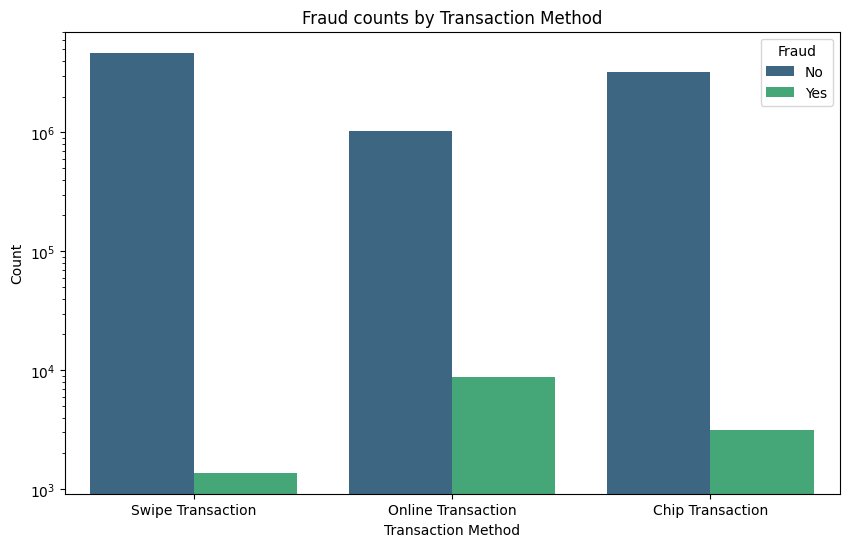

target,No,Yes
use_chip,,
Chip Transaction,99.90,0.10
Online Transaction,99.16,0.84
Swipe Transaction,99.97,0.03


In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=master_df[master_df['target'].notna()], x='use_chip', hue='target', palette='viridis')
plt.title('Fraud counts by Transaction Method')
plt.xlabel('Transaction Method')
plt.ylabel('Count')
plt.yscale('log') # Using log scale because 'No' heavily outweighs 'Yes'
plt.legend(title='Fraud')
plt.show()

chip_target_pct = pd.crosstab(master_df['use_chip'], master_df['target'], normalize='index') * 100
display(chip_target_pct)

**Quick Insight:**
* **High Risk:** **Online Transactions** have the highest fraud rate at **0.84%**, which is over 8x higher than Chip transactions (0.10%).
* **Low Risk:** **Swipe Transactions** show the lowest fraud probability at only **0.03%**.

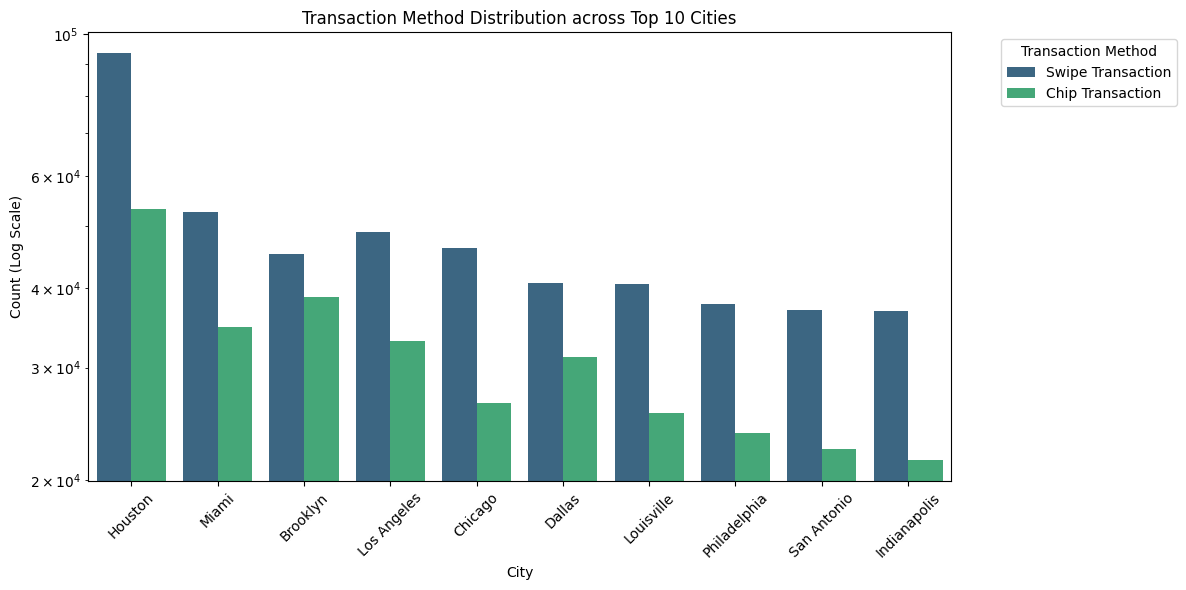

In [ ]:
city_subset = master_df[master_df['merchant_city'].isin(top_10_city.index)]

plt.figure(figsize=(12, 6))
sns.countplot(data=city_subset, x='merchant_city', hue='use_chip', palette='viridis', order=top_10_city.index)
plt.title('Transaction Method Distribution across Top 10 Cities')
plt.xlabel('City')
plt.ylabel('Count (Log Scale)')
plt.yscale('log')
plt.xticks(rotation=45)
plt.legend(title='Transaction Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### merchant_city vs target

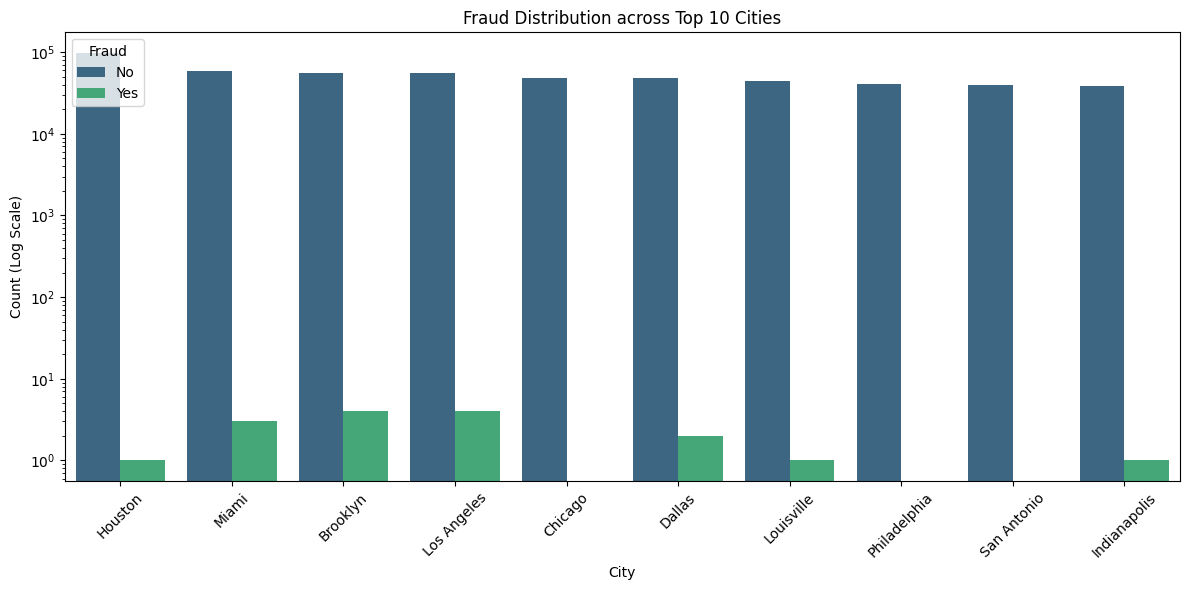

In [50]:
city_subset = master_df[master_df['merchant_city'].isin(top_10_city.index)]

plt.figure(figsize=(12, 6))
sns.countplot(data=city_subset, x='merchant_city', hue='target', palette='viridis', order=top_10_city.index)
plt.title('Fraud Distribution across Top 10 Cities')
plt.xlabel('City')
plt.ylabel('Count (Log Scale)')
plt.yscale('log')
plt.xticks(rotation=45)
plt.legend(title='Fraud', loc='upper left')
plt.tight_layout()
plt.show()

* **Volume-Driven Fraud:** Fraud occurrences are highest in **Houston** and **Miami**, directly correlating with their status as the highest-volume transaction hubs.
* **Distributed Risk:** No single city shows a disproportionately high fraud rate; fraud appears evenly distributed across major urban centers relative to their total transaction counts.
* **Absolute Safety:** Even in top-ranking cities, legitimate transactions outnumber fraud by several orders of magnitude (as seen on the log scale).

In [52]:
chip_target_pct = pd.crosstab(master_df['merchant_city'], master_df['target'], normalize='index') * 100

target,No,Yes
merchant_city,,
Coral Springs,0.00,100.00
Lavon,0.00,100.00
Golf,0.00,100.00
Little Chute,0.00,100.00
Fruitland Park,0.00,100.00
...,...,...
Gorham,100.00,0.00
Gorman,100.00,0.00
Goshen,100.00,0.00


In [57]:
chip_target_pct = chip_target_pct.merge(master_df['merchant_city'].value_counts(), on='merchant_city')
chip_target_pct.sort_values(by='Yes', ascending=False)

,No,Yes,count
merchant_city,,,
Coral Springs,0.00,100.00,1
Lavon,0.00,100.00,1
Golf,0.00,100.00,1
Little Chute,0.00,100.00,2
Fruitland Park,0.00,100.00,5
...,...,...,...
Gorham,100.00,0.00,2028
Gorman,100.00,0.00,5
Goshen,100.00,0.00,1551


In [63]:
chip_target_pct[ (chip_target_pct['count']>5000) & (chip_target_pct['Yes']!=0)].sort_values(by='Yes', ascending=False).head(10)

,No,Yes,count
merchant_city,,,
Rome,43.19,56.81,8092
Online,99.16,0.84,1563700
Marion,99.69,0.31,7739
Bellaire,99.87,0.13,6650
Modesto,99.89,0.11,5491
Wooster,99.91,0.09,8273
Saint Paul,99.93,0.07,8029
Milton,99.93,0.07,9022
Portland,99.94,0.06,14048


In [65]:
master_df[
    master_df['merchant_city'] == 'Rome'
]['target'].value_counts(normalize=True) * 100

,proportion
target,
Yes,56.81
No,43.19


In [67]:
master_df[
    master_df['merchant_city'] == 'Rome'
].sample(10)

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,is_refund,abs_amount,target,target_numeric
12480660,22741588,2019-03-29,19:00:00,267,280,7.27,Chip Transaction,53492,Rome,Italy,NaN,5094,NaN,0,7.27,NaN,NaN
11379910,21379745,2018-06-14,13:28:00,613,2635,-99.00,Chip Transaction,22204,Rome,Italy,NaN,5541,NaN,1,99.00,No,0.00
7969020,17183937,2016-01-03,11:38:00,1451,3226,24.81,Chip Transaction,80114,Rome,Italy,NaN,4121,NaN,0,24.81,No,0.00
4865932,13383213,2013-10-01,13:33:00,1430,2813,62.44,Swipe Transaction,31893,Rome,Italy,NaN,5311,NaN,0,62.44,No,0.00
12309350,22528757,2019-02-12,19:06:00,1283,3469,1.31,Chip Transaction,83018,Rome,Italy,NaN,5310,NaN,0,1.31,Yes,1.00
12429776,22678402,2019-03-16,12:55:00,213,5291,95.02,Chip Transaction,48919,Rome,Italy,NaN,5311,NaN,0,95.02,Yes,1.00
10677269,20514016,2017-12-12,17:13:00,1130,92,102.07,Chip Transaction,88260,Rome,Italy,NaN,5411,NaN,0,102.07,NaN,NaN
12541931,22817470,2019-04-14,22:43:00,1781,6018,87.74,Swipe Transaction,98648,Rome,NY,13440.00,5814,Insufficient Balance,0,87.74,No,0.00
12415533,22660713,2019-03-12,16:50:00,530,4848,87.05,Chip Transaction,83018,Rome,Italy,NaN,5310,NaN,0,87.05,Yes,1.00
11785943,21881436,2018-09-28,14:36:00,1128,3144,7.15,Chip Transaction,49637,Rome,Italy,NaN,3509,NaN,0,7.15,Yes,1.00


In [ ]:
master_df.head()

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,is_refund,abs_amount,target,target_numeric
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.00,5499,NaN,1,77.00,No,0.00
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.00,5311,NaN,0,14.57,No,0.00
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.00,4829,NaN,0,80.00,No,0.00
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.00,4829,NaN,0,200.00,NaN,NaN
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.00,5813,NaN,0,46.41,No,0.00
